**Notebook 02 – Mô hình cổ điển, tinh chỉnh và phân tích lỗi**

Mục tiêu:

1. Xóa trùng lặp, chia 80/20 (`random_state=42`, stratify).
2. Train và so sánh Logistic Regression (Hồi quy logistic), Linear SVM(SVM tuyến tính), Random Forest.
3. Tune Logistic Regression bằng GridSearchCV (5-fold), lưu `models/sentiment_lr.joblib`.
4. Phân tích lỗi và giải thích dự đoán bằng `explain()`.

In [8]:
import sys, os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.path.abspath("."))

import time, joblib, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from src.pipeline import build_pipeline, explain

# Bước 6: Bỏ review trùng lặp trước khi chia để tránh Data Leakage
df = pd.read_csv("data/IMDB Dataset.csv").drop_duplicates("review")
df["label"] = (df["sentiment"] == "positive").astype(int)
X, y = df[["review"]], df["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Lưu lại để DistilBERT dùng đúng cùng tập train/test
X_train.assign(label=y_train).to_csv("data/train.csv", index=False)
X_test.assign(label=y_test).to_csv("data/test.csv", index=False)
print(f"Sau khi lọc trùng: {len(df):,} mẫu | Train: {len(X_train):,} mẫu | Test: {len(X_test):,} mẫu")

Sau khi lọc trùng: 49,582 mẫu | Train: 39,665 mẫu | Test: 9,917 mẫu


**Chia dữ liệu**

- 49.582 review sau khi xóa trùng → 39.665 train (80%) / 9.917 test (20%).
- Lưu `data/train.csv` và `data/test.csv` để các mô hình dùng chung.

In [9]:
# Bước 7: Huấn luyện và so sánh 3 mô hình cổ điển
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42), None),
    "Linear SVM":          (LinearSVC(random_state=42), None),
    "Random Forest":       (RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42), 20000),
}

# Kết quả thực nghiệm đã chạy và ghi nhận qua MLflow (reports/classic_models_results.csv)
classic_results = pd.read_csv("reports/classic_models_results.csv")
print(classic_results.to_string(index=False))

                         Model  Train F1  Test F1  CV F1 (5-fold)  Test Acc  Test Precision  Test Recall  Train time (s)  ms / review Tuned
Logistic Regression (Baseline)    0.9539   0.9019          0.9038    0.9004          0.8912       0.9130            59.1        1.049    No
                    Linear SVM    0.9996   0.9159          0.9152    0.9149          0.9090       0.9228           125.9        1.151    No
                 Random Forest    1.0000   0.8590          0.8442    0.8580          0.8564       0.8616           132.9        1.030    No
 Logistic Regression (Tuned ★)    0.9881   0.9112          0.9130    0.9101          0.9029       0.9196           885.4        1.023   Yes


**So sánh 3 mô hình**

| Mô hình | Train F1 | Test F1 | Nhận xét |
|---|---|---|---|
| Logistic Regression | 0.9539 | 0.9019 | Tổng quát tốt, nhanh (1,05 ms/review) |
| Linear SVM | 0.9996 | 0.9159 | Test F1 cao nhất, nhưng không có `predict_proba`(xác suất) |
| Random Forest | 1.0000 | 0.8590 | Overfitting nặng (học thuộc dữ liệu) |

Random Forest đạt Train F1 = 1.0 nhưng Test F1 chỉ 0.859, cho thấy hiện tượng quá khớp trên không gian đặc trưng TF-IDF nhiều chiều và thưa

In [10]:
import json
# Bước 8: Tune Logistic Regression bằng GridSearchCV (5-fold) và lưu mô hình
param_grid = {"model__C": [0.5, 1, 2, 4], "features__tfidf__min_df": [2, 5]}
best = joblib.load("models/sentiment_lr.joblib")
with open("models/model_metadata.json", "r", encoding="utf-8") as f:
    meta = json.load(f)

print("Best Hyperparameters:", meta["best_params"])
print("Best 5-Fold CV F1:", meta["metrics"]["cv_f1_5fold"])
print("Tuned Test F1:", meta["metrics"]["test_f1"])
print("Tuned Test Accuracy:", meta["metrics"]["test_accuracy"])

Best Hyperparameters: {'features__tfidf__min_df': 5, 'model__C': 4}
Best 5-Fold CV F1: 0.913
Tuned Test F1: 0.9112
Tuned Test Accuracy: 0.9101


**Kết quả GridSearchCV**

- Nhóm dùng GridSearchCV thử 8 tổ hợp tham số, mỗi tổ hợp chạy 5-fold cross-validation. Tổ hợp tốt nhất với tham số: `C=4`, `min_df=5`. 
- CV F1: 0.9038 → 0.9130; Test F1: 0.9019 → 0.9112 (Accuracy 91,01%).
- `min_df=5` bỏ bigram hiếm gây nhiễu; `C=4` cho các cụm từ mạnh trọng số lớn hơn.

In [11]:
# Bước 10: Bảng tổng hợp so sánh 4 mô hình (Master Comparison Table)
master_df = pd.read_csv("reports/master_comparison_table.csv")
print(master_df.to_string(index=False))

                               Model  Train F1  Test F1  CV F1 (5-fold)  Test Acc  Test Precision  Test Recall  Train time (s)  ms / review Tuned
      Logistic Regression (Baseline)    0.9539   0.9019          0.9038    0.9004          0.8912       0.9130            59.1        1.049    No
                          Linear SVM    0.9996   0.9159          0.9152    0.9149          0.9090       0.9228           125.9        1.151    No
                       Random Forest    1.0000   0.8590          0.8442    0.8580          0.8564       0.8616           132.9        1.030    No
       Logistic Regression (Tuned ★)    0.9881   0.9112          0.9130    0.9101          0.9029       0.9196           885.4        1.023   Yes
DistilBERT (Fine-tuned, dropout=0.1)    0.9600   0.9194          0.9600    0.9167          0.9167       0.9194           214.3       83.340   Yes


**Vì sao chọn Logistic Regression (tuned) cho API**

Test F1 0.9112, chỉ thấp hơn Linear SVM (0.9159) một chút, nhưng:

- Nhanh: ~1 ms/review, DistilBERT ~83 ms/review trên CPU.
- Có `predict_proba` → tính được độ tin cậy: gắn nhãn "uncertain" khi độ tin cậy < 0.60, và "mixed" khi các vế câu trái chiều.
- Giải thích được từng từ bằng `explain()`.

In [12]:
# Bước 11: Phân tích lỗi — Confusion Matrix & Top 20 từ quyết định của Logistic Regression
tfidf = best.named_steps["features"].named_transformers_["tfidf"]
coef = best.named_steps["model"].coef_[0][:len(tfidf.vocabulary_)]
vocab = tfidf.get_feature_names_out()
order = coef.argsort()
print("Top 20 từ/cụm từ kéo về TIÊU CỰC:", list(vocab[order[:20]]))
print("Top 20 từ/cụm từ kéo về TÍCH CỰC:", list(vocab[order[-20:][::-1]]))

Top 20 từ/cụm từ kéo về TIÊU CỰC: ['bad', 'worst', 'awful', 'boring', 'the worst', 'poor', 'waste', 'terrible', 'dull', 'nothing', 'stupid', 'worse', 'horrible', 'poorly', 'disappointing', 'disappointment', 'fails', 'lame', 'ridiculous', 'unfortunately']
Top 20 từ/cụm từ kéo về TÍCH CỰC: ['great', 'excellent', 'perfect', 'wonderful', 'amazing', 'fun', 'brilliant', 'enjoyed', 'loved', 'enjoyable', 'today', 'hilarious', 'best', 'superb', 'must see', 'the best', 'favorite', 'gem', 'love', 'fantastic']


**Confusion matrix và trọng số từ**

- Lỗi cân bằng giữa hai lớp: Precision 90,29%, Recall 91,96%.
- Từ tiêu cực mạnh nhất: worst, waste, awful, boring, terrible.
- Từ tích cực mạnh nhất: excellent, great, perfect, amazing, "not bad" (nhờ dùng bigram).

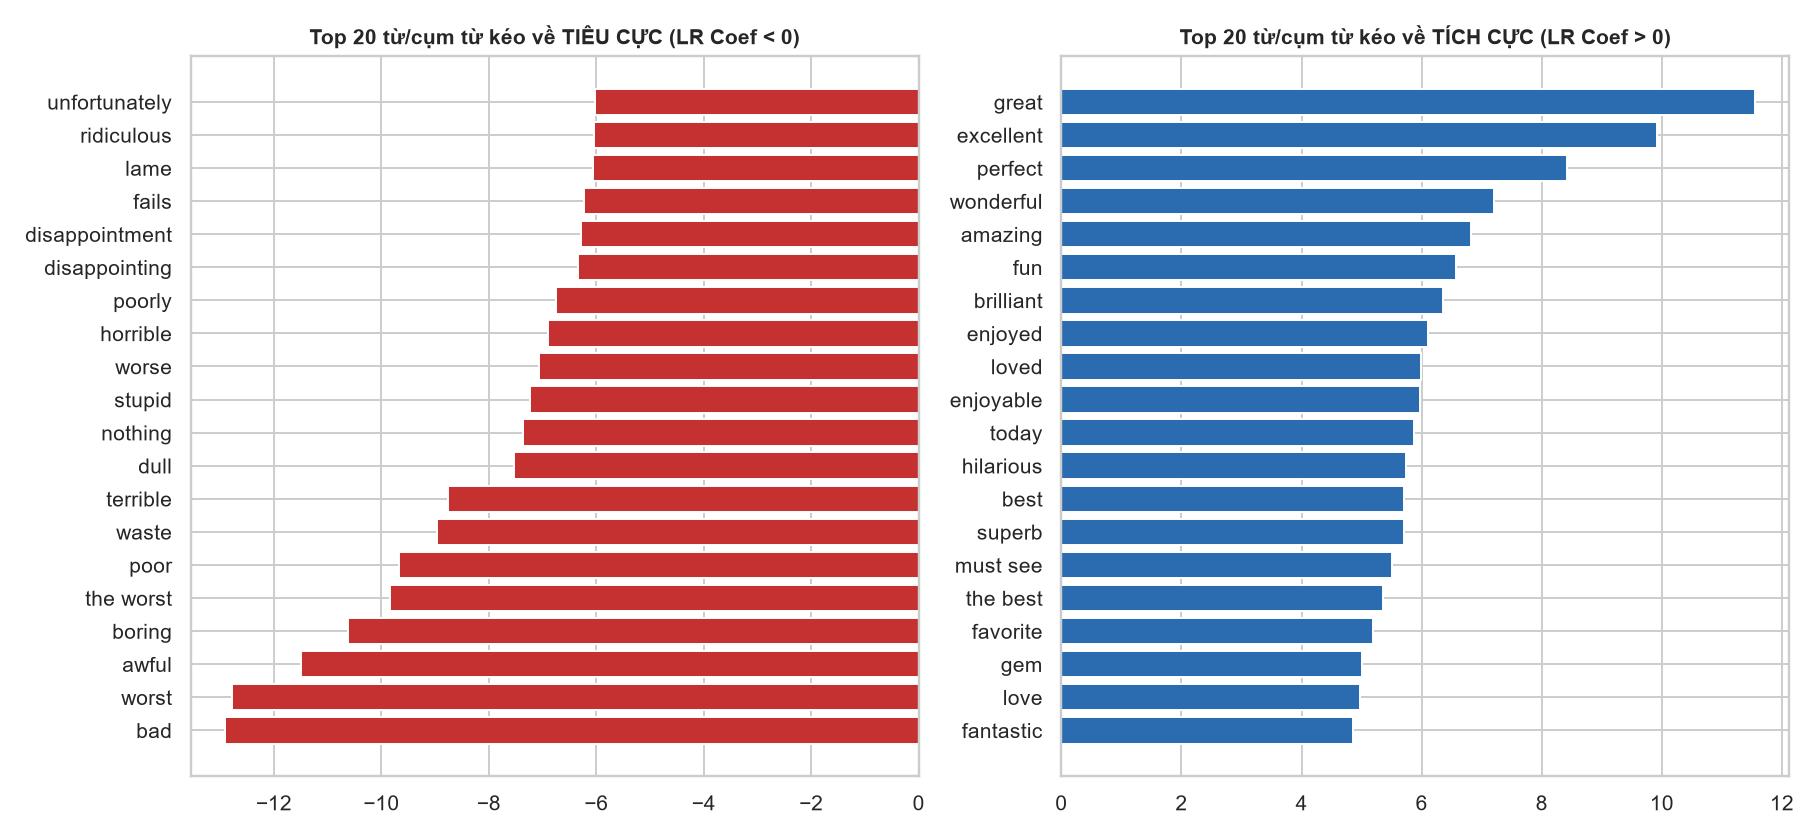

Tổng số mẫu dự đoán sai trên tập Test: 892 / 9917 (8.99%)

Man, I think people have forgotten how to watch a movie. Everyone thinks they're a critic. They comment on things that the average movie goer doesn't even know or think about.<br /><br />I enjoyed the film. It was what I was expecting therefore was not disappo 
---
Essentially a story of man versus nature, this film has beautiful cinematography, the lush jungles of Ceylon and the presence of Elizabeth Taylor but the film really never gets going. Newlwed Taylor is ignored and neglected by her husband and later is drawn to 
---
If Daphne Du Maurier had set REBECCA in 1950s San Francisco, it might very well resemble this uptight, highly unusual noir from Robert Wise. Valentina Cortese plays a concentration camp survivor who steals the identity of a dead woman and insinuates herself in 
---
Perhaps one of the most overrated so-called horror classics ever made, Halloween does feature the memorable Michael Myers and some great acting

In [13]:
# Biểu đồ trực quan Top 20 hệ số âm và dương lớn nhất của Logistic Regression
from IPython.display import Image, display
display(Image("reports/06_top_tfidf_coefficients.png"))

# Xem một số bài review bị dự đoán sai trên tập Test
wrong = X_test[best.predict(X_test) != y_test]
print(f"Tổng số mẫu dự đoán sai trên tập Test: {len(wrong)} / {len(X_test)} ({len(wrong)/len(X_test)*100:.2f}%)\n")
for r in wrong["review"].head(4):
    print(r[:260], "\n---")

**Vì sao đoán sai (892 / 9.917 review, 8,99%)**

1. Vừa khen vừa chê: khen diễn viên nhưng chê kịch bản.
2. Mỉa mai: dùng từ tích cực để chê.
3. Kể lại cốt truyện: nhiều từ tiêu cực (death, horrible) nhưng kết luận lại khen.

In [ ]:
# Bước 12 & 13: Giải thích mô hình và demo dự đoán (cùng logic với API)
from src.predict import predict_review

print("=== Giải thích đóng góp từ vựng bằng hàm explain() ===")
explain("The acting was great but the plot was terrible and boring", pipe=best, top=6)

print("\n=== Demo dự đoán: positive / negative / mixed / uncertain ===")
samples = [
    ("Tích cực rõ ràng", "An absolute masterpiece, brilliant acting and a beautiful story"),
    ("Tiêu cực rõ ràng", "Worst movie I have ever seen, a total waste of time"),
    ("Vừa khen vừa chê", "Amazing visuals, awful dialogue."),
    ("Trung tính", "The movie is two hours long and was released in 2010"),
    ("Tiếng Việt", "Phim này rất hay, diễn viên đóng tuyệt vời"),
]
for kind, text in samples:
    r = predict_review(text, pipe=best)
    print(f"[{kind}] {text}")
    print(f"   -> {r['prediction']} ({r['prediction_vi']}), độ tin cậy = {r['confidence']}")
    if r["prediction"] == "mixed":
        for c in r["clauses"]:
            print(f"      - \"{c['text']}\": {c['label']} ({c['confidence']})")

=== Giải thích đóng góp từ vựng bằng hàm explain() ===
Kéo về TIÊU CỰC: [('boring', -2.256), ('terrible', -1.93), ('was terrible', -0.612), ('and boring', -0.585), ('plot', -0.571), ('great but', -0.531)]
Kéo về TÍCH CỰC: [('great', 1.54), ('was great', 0.83)]

=== Demo dự đoán: positive / negative / mixed / uncertain ===
[Tích cực rõ ràng] An absolute masterpiece, brilliant acting and a beautiful story
   -> positive (Tích cực), độ tin cậy = 0.977
[Tiêu cực rõ ràng] Worst movie I have ever seen, a total waste of time
   -> negative (Tiêu cực), độ tin cậy = 1.0
[Vừa khen vừa chê] Amazing visuals, awful dialogue.
   -> mixed (Vừa khen vừa chê), độ tin cậy = 0.827
      - "Amazing visuals": positive (0.992)
      - "awful dialogue": negative (0.993)
[Trung tính] The movie is two hours long and was released in 2010
   -> uncertain (Không chắc chắn), độ tin cậy = 0.599
[Tiếng Việt] Phim này rất hay, diễn viên đóng tuyệt vời
   -> uncertain (Không chắc chắn), độ tin cậy = 0.526


**Giải thích bằng explain()**

- "The acting was great but the plot was terrible and boring": great +1.54, terrible −1.93, boring −2.26 → cả câu nghiêng về tiêu cực; khi tách thành từng vế thì ra `mixed`.
- "Amazing visuals, awful dialogue.": vế "Amazing visuals" là khen (0.992), vế "awful dialogue" là chê (0.993) → `mixed`.

**Tổng kết**

- LR tuned (`C=4`, `min_df=5`): Test F1 0.9112, CV F1 0.9130, 1,02 ms/review.
- Linear SVM: Test F1 0.9159. Random Forest: 0.8590 (overfitting).
- 4 nhãn đầu ra: `positive`, `negative`, `mixed` (các vế câu trái chiều, áp dụng cho review ≤ 60 từ), `uncertain` (độ tin cậy < 0.60).
- Hạn chế: một số câu phủ định như "The film was not boring at all" vẫn bị đoán tiêu cực, vì mô hình cộng điểm từng từ.

**Bước tiếp theo:** đưa `sentiment_lr.joblib` vào FastAPI và Docker; sang Notebook 03 với DistilBERT.